# 2026.10.22(목) 22h~

In [1]:
import numpy as np                         # 숫자 배열을 계산하는 도구
import matplotlib.pyplot as plt            # 숫자를 그래프로 보는 도구
from IPython.display import Audio, display # 노트북 안에 재생 버튼을 표시하는 도구
from pathlib import Path                   # 파일 위치를 표현하는 도구
import json                                # 작은 결과 기록을 저장하는 도구
import matplotlib.font_manager as fm

# 그래프에 한글을 표시합니다. 이 준비 코드는 수정하지 않고 실행합니다.
available_fonts = {font.name for font in fm.fontManager.ttflist}
for font_name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if font_name in available_fonts:
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (10, 3)
plt.rcParams["figure.dpi"] = 110

SR = 16000  # 이번 기초 실습의 기준: 1초에 16,000개. 모든 모델의 공통 규격이라는 뜻은 아닙니다.
print("준비 완료 / 이번 실습의 SR:", SR)

준비 완료 / 이번 실습의 SR: 16000


In [2]:
from scipy.io import wavfile

def read_pcm16(path):
    """PCM16 파일 → (샘플링레이트, 계산용 실수 배열). 채널은 그대로 둡니다."""
    sr, integers = wavfile.read(path)
    if integers.dtype != np.int16:
        raise ValueError("이번 실습에는 16비트 정수 PCM WAV를 사용하세요.")
    if sr <= 0 or integers.size == 0:
        raise ValueError("SR이 올바르고 샘플이 들어 있는 WAV가 필요합니다.")
    if integers.ndim not in (1, 2):
        raise ValueError("모노 또는 채널 축이 있는 WAV가 필요합니다.")
    sound = integers.astype(np.float32) / 32768.0  # 정수 → 실수 → 크기 눈금 변환
    return int(sr), sound

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
sample_path = DATA_DIR / "tone_sequence_16k_mono.wav"
if not sample_path.exists():
    # 2초 예제: 0.20~0.80초 440Hz, 1.00~1.60초 880Hz, 나머지는 무음
    sample_times = np.arange(2 * SR) / SR
    generated = np.zeros(2 * SR, dtype=np.float32)
    for start, end, hz in [(0.20, 0.80, 440), (1.00, 1.60, 880)]:
        mask = (sample_times >= start) & (sample_times < end)
        generated[mask] = 0.35 * np.sin(2 * np.pi * hz * sample_times[mask])
    wavfile.write(sample_path, SR, np.round(generated * 32767).astype(np.int16))
    print("예제 합성음 생성:", sample_path)

In [3]:
sr, audio = read_pcm16(sample_path)
print("공통 파일:", sample_path.name, "/", sr, "Hz /", len(audio) / sr, "초")
display(Audio(audio, rate=sr, normalize=False))

공통 파일: tone_sequence_16k_mono.wav / 16000 Hz / 2.0 초


## 실습1. 전체 주파수 보기

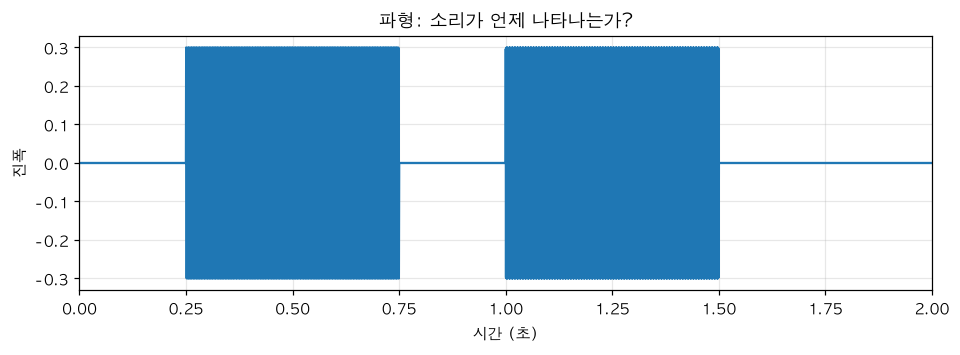

In [4]:
time = np.arange(len(audio)) / sr
plt.figure()
plt.plot(time, audio)
plt.xlabel("시간 (초)")
plt.ylabel("진폭")
plt.title("파형: 소리가 언제 나타나는가?")
plt.xlim(0, 2)
plt.grid(alpha=0.3)
plt.show()

## 실습2. FFT?

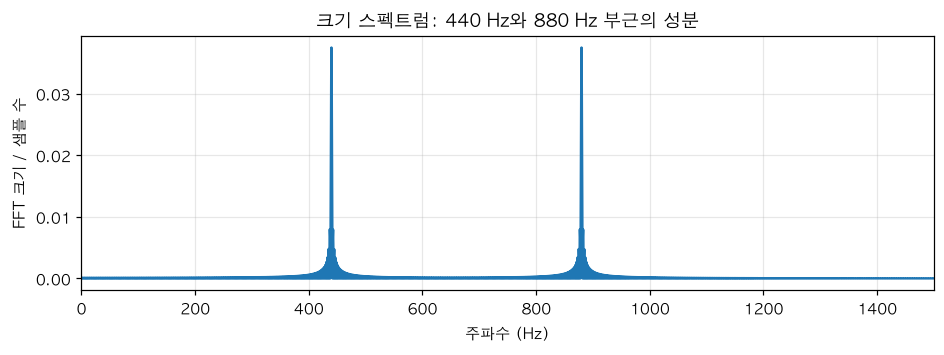

In [ ]:
# 1. 음성 신호를 FFT로 변환 -> fft_result는 크기 및 위상을 가짐
# 시간 영역의 음성 데이터를 주파수 영역으로 변환합니다.
# rfft()는 실수 신호에서 중복되는 음의 주파수 영역을 생략합니다.
fft_result = np.fft.rfft(audio)

# 2. 각 주파수 성분의 크기 계산
# FFT 결과는 복소수이므로 abs()로 크기(Magnitude)를 구합니다.
# 샘플 수로 나누어 신호 길이에 따른 크기 차이를 일부 보정합니다.
fft_size = np.abs(fft_result) / len(audio)

# 3. FFT 결과에 대응하는 주파수 계산
# 각 FFT 결과가 몇 Hz에 해당하는지 구합니다.
# d는 샘플 하나를 측정하는 시간 간격(1 / sr)입니다.
frequency_axis = np.fft.rfftfreq(len(audio), d=1 / sr)

# 4. 주파수별 크기를 그래프로 표시
plt.figure()
plt.plot(frequency_axis, fft_size)

plt.xlabel("주파수 (Hz)")          # X축: 주파수
plt.ylabel("FFT 크기 / 샘플 수")    # Y축: 주파수 성분의 크기
plt.title("크기 스펙트럼: 440 Hz와 880 Hz 부근의 성분")

plt.xlim(0, 1500)                  # 0~1500Hz 범위만 표시
plt.grid(alpha=0.3)                # 그래프에 보조 눈금 표시
plt.show()

## 실습3. 한 구간의 주된 봉우리 읽기

In [7]:
# 1. 첫 번째 음이 포함된 0.25~0.75초 구간 추출
# 시간(초)에 샘플링 레이트(sr)를 곱하면 샘플 위치가 됩니다.
first_part = audio[int(0.25 * sr):int(0.75 * sr)]

# 2. 선택한 구간을 FFT로 분석
# rfft(): 주파수 성분 계산
# abs(): 각 주파수 성분의 크기 추출
part_fft = np.abs(np.fft.rfft(first_part))

# 3. FFT 결과의 각 칸에 해당하는 주파수(Hz) 계산
part_hz = np.fft.rfftfreq(len(first_part), d=1 / sr)

# 4. 가장 큰 FFT 크기를 가진 칸 번호 찾기
peak_index = int(np.argmax(part_fft))

# 5. 해당 칸 번호를 실제 주파수(Hz)로 변환하여 출력
print("첫 번째 음의 가장 큰 봉우리:", part_hz[peak_index], "Hz")

첫 번째 음의 가장 큰 봉우리: 440.0 Hz


## 2026-10-22(목) 수업 리뷰 — 03 FFT·STFT (오늘은 FFT 도입까지)

수치는 `data/tone_sequence_16k_mono.wav`를 직접 읽어 계산해서 확인했습니다. 노트북 제목에 STFT가 있지만 **오늘 셀에는 FFT까지만** 있습니다(다음에 STFT가 이어질 것이라는 건 제목에 근거한 추정입니다).

### 1. 오늘 한 것
| 셀 | 내용 | 결과 |
|---|---|---|
| 6 | 파형(시간 → 진폭) | "소리가 언제 나타나는가"만 보임 |
| 8 | 전체 FFT(주파수 → 크기) | 440 Hz와 880 Hz에 봉우리 2개 ✓ |
| 10 | 0.25~0.75초 구간만 FFT, `argmax`로 봉우리 찾기 | **440.0 Hz** ✓ (직접 재현해서 일치) |

### 2. 숫자로 읽기 (직접 계산)
**전체 FFT (8번 셀)**
- 샘플 32000개 → `rfft` 결과 **16001칸**(= N/2 + 1), 칸 간격 **0.5 Hz**(= 16000 ÷ 32000).
- 440 Hz 칸(880번)과 880 Hz 칸(1760번)의 크기가 모두 **0.0375**로 같습니다. 두 소리의 진폭(0.3)과 길이(0.5초)가 같기 때문입니다.
- 왜 0.0375인가: `0.3(진폭) ÷ 2 × 0.5초 ÷ 2초(전체 길이) = 0.0375`. 사인파의 FFT 크기는 `진폭 ÷ 2`이고, 소리가 전체 길이 중 일부만 차지하면 그 비율만큼 줄어들기 때문입니다(`/ len(audio)`로 샘플 수를 나눈 값이므로).
- 이 값은 "소리의 크기" 그 자체가 아니라 **"전체 2초 중 이 주파수가 얼마나 담겨 있나"** 입니다. 그래서 그래프의 y축 이름이 `FFT 크기 / 샘플 수`입니다.
- 봉우리 바로 옆(879.5 Hz)에도 `0.0338`이 있습니다. 봉우리가 한 칸이 아니라 **폭을 가지고** 퍼져 보이는 이유입니다(소리가 중간에 켜지고 꺼지는 짧은 소리라서, 직접 확인한 값).
- 봉우리 주변을 제외한 나머지 주파수의 최대 크기는 `0.0005`로 훨씬 작습니다.

**구간 FFT (10번 셀)**
- 구간 길이 0.5초 = **8000개** → 칸 간격 **2 Hz**(= 16000 ÷ 8000 = 1 ÷ 0.5초).
- 봉우리 크기 `1200`(= `진폭 0.3 × 8000 ÷ 2`)로, 이 셀은 `/ len` 없이 `abs`만 했기 때문에 숫자가 큽니다(8번 셀과 숫자를 직접 비교하면 안 됩니다).
- 정확히 `440.0 Hz`가 나온 이유: 0.5초 안에 **220주기**가 딱 들어가고, 칸 간격 2 Hz에 440이 딱 맞기 때문입니다(`440 ÷ 2 = 220`번째 칸). 시작·끝이 파형의 같은 위상이라 봉우리가 한 칸에 모입니다.
- 구간을 `0.2~0.8초`(0.6초, 칸 간격 1.67 Hz)로 바꿔도 `argmax`는 `440.0 Hz`를 찾습니다(직접 실행). 880 Hz 구간(`1.0~1.5초`)은 `880.0 Hz`.

### 3. 핵심 개념 (오늘 실습의 요점)
- **FFT는 "어떤 주파수가 얼마나 들어 있나"만 알려 주고 "언제"는 알려 주지 않습니다.** 8번 셀에서 440 Hz와 880 Hz 봉우리 크기가 같다는 것만 보이고, 어느 소리가 먼저인지는 그래프에 없습니다. 파형(6번 셀)은 반대입니다(언제는 보이지만 몇 Hz인지는 안 보임).
- 그래서 **구간을 나눠서** FFT를 하면 "언제 + 몇 Hz"를 함께 볼 수 있습니다. 10번 셀(0.25~0.75초만 FFT)이 그 첫걸음입니다. 구간 FFT를 시간 순서로 계속 이어 가는 것이 STFT라고 설명되는 개념입니다(일반 지식, 오늘 수업에서 어떻게 다룰지는 확인하지 못함).
- **칸 간격(주파수 해상도) = SR ÷ 구간의 샘플 수 = 1 ÷ 구간의 길이(초).** 구간이 짧을수록 칸이 넓어집니다(0.5초 → 2 Hz, 2초 → 0.5 Hz). "짧은 구간 ↔ 정밀한 주파수"는 서로 맞바꾸는 관계입니다.
- 주파수로 읽는 공식: **칸 번호 × 칸 간격 = Hz** (예: `880번 × 0.5 = 440 Hz`). 10번 셀의 `part_hz[peak_index]`가 바로 이 계산입니다.

### 4. 알아 둘 점 (★)
- **3번 셀의 "예제 합성음 생성" 코드는 실제 데이터 파일과 다른 소리를 만듭니다.** 코드는 `0.20~0.80초 440 Hz / 1.00~1.60초 880 Hz / 진폭 0.35`인데, 지금 `data/tone_sequence_16k_mono.wav`는 `0.25~0.75초 440 Hz / 1.00~1.50초 880 Hz / 진폭 0.3`입니다(앞 수업의 `7475` 계산과 이번 FFT 크기 0.0375로 확인). **파일이 있으면 생성 코드가 실행되지 않으니 지금은 문제가 없습니다.** 파일이 없는 환경에서 실행하면 봉우리 크기가 `0.0525`(= 0.35 ÷ 2 × 0.6 ÷ 2, 계산값, 실행하지는 않음)로 달라지고, 10번 셀의 0.25~0.75초 구간도 소리 길이와 달라집니다. 같은 이름의 파일을 만들어 놓는 코드이므로 02 노트북의 파일과 어긋날 수 있다는 것만 알아 두세요.
- 같은 3번 셀이 `np.round(generated * 32767)`을 쓰는데, 앞 수업의 읽기 코드는 `÷ 32768`입니다. 값이 `1/32768` 이하로 아주 조금 다를 뿐 소리에는 영향이 없습니다.
- **8번 셀은 실행 번호가 없습니다**(저장된 그래프만 있음). 셀을 고친 뒤 다시 실행하지 않았을 수 있으니, 처음부터 `Restart & Run All`을 한 번 해 보세요.
- 빈 코드 셀이 3개(1, 11, 12번) 있습니다.
- 03 노트북은 아직 git에 추적되지 않은 새 파일이고, 재생기는 합성음 1개뿐이라 목소리나 경로 문제는 없습니다(경로 출력 없음 확인).

### 5. 직접 해 보면 좋은 것 (코드는 직접 작성해 보세요)
1. 880 Hz 구간(`1.0~1.5초`)도 같은 방법으로 봉우리를 찾기.
2. 구간을 `0.2~0.8초`나 `0.3~0.7초`로 바꾸고 칸 간격(`part_hz[1]`)과 봉우리 위치가 어떻게 변하는지 보기.
3. 소리가 **없는 구간**(`0.8~1.0초`)을 FFT하면 봉우리가 어떻게 나오는지 보기(무음이라 크기가 0에 가깝고, `argmax`는 의미 없는 값을 돌려줍니다 → "봉우리가 있다"는 것을 먼저 확인해야 함).
4. 02 노트북의 내 목소리(`data/my_voice.wav`)를 16000 Hz로 바꿔 구간 FFT를 하면 가장 센 주파수가 약 **250 Hz 근처**인지 확인(어제 계산에서 나온 값).
